In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [30]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("../data/raw")

customers = pd.read_csv(DATA_DIR / "olist_customers_dataset.csv")
orders = pd.read_csv(DATA_DIR / "olist_orders_dataset.csv")
order_items = pd.read_csv(DATA_DIR / "olist_order_items_dataset.csv")
order_payments = pd.read_csv(DATA_DIR / "olist_order_payments_dataset.csv")
order_reviews = pd.read_csv(DATA_DIR / "olist_order_reviews_dataset.csv")
products = pd.read_csv(DATA_DIR / "olist_products_dataset.csv")
sellers = pd.read_csv(DATA_DIR / "olist_sellers_dataset.csv")
category_translation = pd.read_csv(
    DATA_DIR / "product_category_name_translation.csv"
)

print("Datasets loaded successfully!")
print("Customers:", customers.shape)
print("Orders:", orders.shape)
print("Order items:", order_items.shape)
print("Payments:", order_payments.shape)
print("Reviews:", order_reviews.shape)
print("Products:", products.shape)
print("Sellers:", sellers.shape)
print("Category translations:", category_translation.shape)

Datasets loaded successfully!
Customers: (99441, 5)
Orders: (99441, 8)
Order items: (112650, 7)
Payments: (103886, 5)
Reviews: (99224, 7)
Products: (32951, 9)
Sellers: (3095, 4)
Category translations: (71, 2)


In [31]:
display(orders.head())

print("\nDataset information:")
orders.info()

print("\nMissing values:")
display(orders.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:", orders.duplicated().sum())

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB

Missing values:


order_delivered_customer_date    2965
order_delivered_carrier_date     1783
order_approved_at                 160
order_id                            0
order_purchase_timestamp            0
order_status                        0
customer_id                         0
order_estimated_delivery_date       0
dtype: int64


Duplicate rows: 0


In [32]:
# Convert order date columns from strings to datetime
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders[column] = pd.to_datetime(orders[column], errors="coerce")

print("Date conversion completed!")
orders.info()

Date conversion completed!
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  datetime64[us]
 5   order_delivered_carrier_date   97658 non-null  datetime64[us]
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
dtypes: datetime64[us](5), str(3)
memory usage: 6.1 MB


In [33]:
# Check missing values by order status
missing_by_status = (
    orders.groupby("order_status")
    .agg(
        total_orders=("order_id", "count"),
        missing_approval=("order_approved_at", lambda x: x.isna().sum()),
        missing_carrier_date=(
            "order_delivered_carrier_date",
            lambda x: x.isna().sum()
        ),
        missing_delivery_date=(
            "order_delivered_customer_date",
            lambda x: x.isna().sum()
        )
    )
    .sort_values("total_orders", ascending=False)
)

display(missing_by_status)

,total_orders,missing_approval,missing_carrier_date,missing_delivery_date
order_status,,,,
delivered,96478,14,2,8
shipped,1107,0,0,1107
canceled,625,141,550,619
unavailable,609,0,609,609
invoiced,314,0,314,314
processing,301,0,301,301
created,5,5,5,5
approved,2,0,2,2


In [34]:
# Check primary-key uniqueness
print("Duplicate order IDs:", orders["order_id"].duplicated().sum())

# Check invalid date relationships
print(
    "Approval before purchase:",
    (orders["order_approved_at"] < orders["order_purchase_timestamp"]).sum()
)

print(
    "Delivery before purchase:",
    (
        orders["order_delivered_customer_date"]
        < orders["order_purchase_timestamp"]
    ).sum()
)

print(
    "Estimated delivery dates before purchase:",
    (
        orders["order_estimated_delivery_date"]
        < orders["order_purchase_timestamp"]
    ).sum()
)

# Review order statuses
display(orders["order_status"].value_counts().to_frame("order_count"))

Duplicate order IDs: 0
Approval before purchase: 0
Delivery before purchase: 0
Estimated delivery dates before purchase: 0


,order_count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


In [35]:

# Monthly sales trend analysis

# Keep delivered orders for this analysis
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

# Join orders with order items
sales_data = delivered_orders[
    ["order_id", "order_purchase_timestamp"]
].merge(
    order_items[["order_id", "price", "freight_value"]],
    on="order_id",
    how="inner",
    validate="one_to_many"
)

# Create a monthly summary
sales_data["sales_month"] = (
    sales_data["order_purchase_timestamp"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly_sales = (
    sales_data.groupby("sales_month")
    .agg(
        product_revenue=("price", "sum"),
        freight_revenue=("freight_value", "sum"),
        order_count=("order_id", "nunique")
    )
    .reset_index()
)

monthly_sales["total_sales"] = (
    monthly_sales["product_revenue"]
    + monthly_sales["freight_revenue"]
)

display(monthly_sales.head())
print("Months analyzed:", len(monthly_sales))
print("Total product revenue:", round(monthly_sales["product_revenue"].sum(), 2))
print("Total freight revenue:", round(monthly_sales["freight_revenue"].sum(), 2))


,sales_month,product_revenue,freight_revenue,order_count,total_sales
0,2016-09-01,134.97,8.49,1,143.46
1,2016-10-01,"40,325.11","6,165.55",265,"46,490.66"
2,2016-12-01,10.90,8.72,1,19.62
3,2017-01-01,"111,798.36","15,684.01",750,"127,482.37"
4,2017-02-01,"234,223.40","37,015.92",1653,"271,239.32"


Months analyzed: 23
Total product revenue: 13221498.11
Total freight revenue: 2198275.64


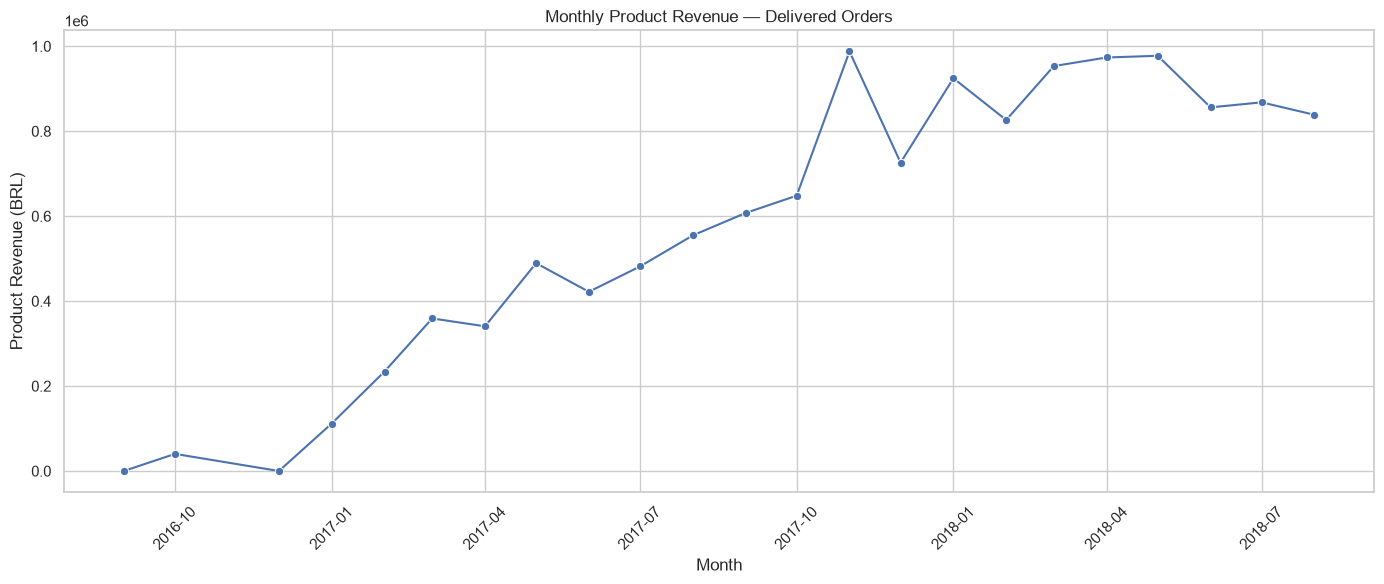

In [36]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_sales,
    x="sales_month",
    y="product_revenue",
    marker="o"
)

plt.title("Monthly Product Revenue — Delivered Orders")
plt.xlabel("Month")
plt.ylabel("Product Revenue (BRL)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [37]:
# Analyze customer purchase frequency

delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

customer_orders = (
    delivered_orders
    .groupby("customer_id")
    .agg(
        order_count=("order_id", "nunique"),
        first_order=("order_purchase_timestamp", "min"),
        last_order=("order_purchase_timestamp", "max")
    )
    .reset_index()
)

# Classify customers by number of delivered orders
customer_orders["customer_type"] = np.where(
    customer_orders["order_count"] > 1,
    "Repeat Customer",
    "One-Time Customer"
)

customer_summary = (
    customer_orders["customer_type"]
    .value_counts()
    .rename_axis("customer_type")
    .reset_index(name="customer_count")
)

customer_summary["percentage"] = (
    customer_summary["customer_count"]
    / customer_summary["customer_count"].sum()
    * 100
)

display(customer_summary.round(2))

print("Total customers:", customer_orders["customer_id"].nunique())
print(
    "Repeat purchase rate:",
    round(
        (customer_orders["order_count"] > 1).mean() * 100,
        2
    ),
    "%"
)

,customer_type,customer_count,percentage
0,One-Time Customer,96478,100.00


Total customers: 96478
Repeat purchase rate: 0.0 %


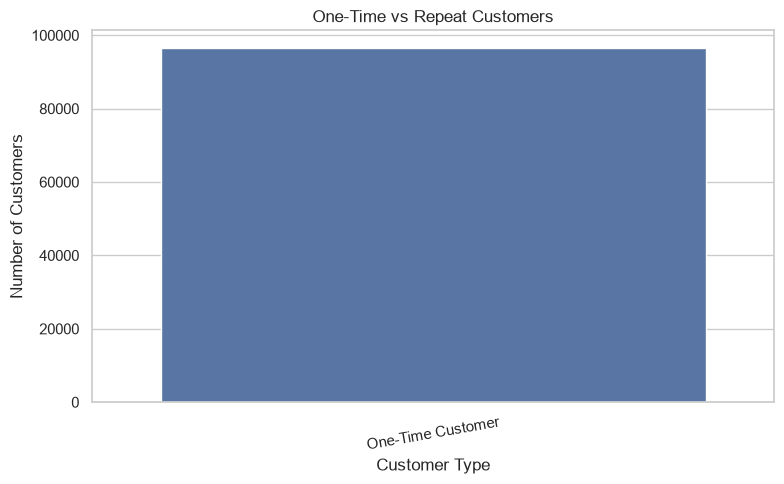

In [38]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=customer_summary,
    x="customer_type",
    y="customer_count"
)

plt.title("One-Time vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

In [39]:
# Correct customer retention analysis using customer_unique_id

# Keep delivered orders and attach the unique customer identifier
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

customer_purchase_data = delivered_orders[
    ["order_id", "customer_id", "order_purchase_timestamp"]
].merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left",
    validate="one_to_one"
)

# Count delivered orders per unique customer
unique_customer_orders = (
    customer_purchase_data
    .groupby("customer_unique_id")
    .agg(
        order_count=("order_id", "nunique"),
        first_order=("order_purchase_timestamp", "min"),
        last_order=("order_purchase_timestamp", "max")
    )
    .reset_index()
)

# Classify customers
unique_customer_orders["customer_type"] = np.where(
    unique_customer_orders["order_count"] > 1,
    "Repeat Customer",
    "One-Time Customer"
)

# Summarize customer types
customer_summary = (
    unique_customer_orders["customer_type"]
    .value_counts()
    .rename_axis("customer_type")
    .reset_index(name="customer_count")
)

customer_summary["percentage"] = (
    customer_summary["customer_count"]
    / customer_summary["customer_count"].sum()
    * 100
)

display(customer_summary.round(2))

print(
    "Total unique customers:",
    unique_customer_orders["customer_unique_id"].nunique()
)

print(
    "Repeat purchase rate:",
    round(
        (
            unique_customer_orders["order_count"] > 1
        ).mean() * 100,
        2
    ),
    "%"
)

,customer_type,customer_count,percentage
0,One-Time Customer,90557,97.00
1,Repeat Customer,2801,3.00


Total unique customers: 93358
Repeat purchase rate: 3.0 %


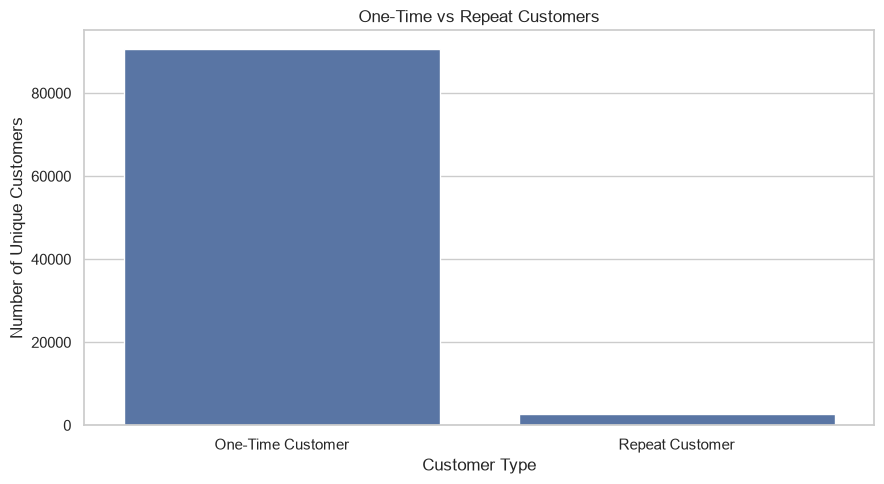

In [40]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=customer_summary,
    x="customer_type",
    y="customer_count"
)

plt.title("One-Time vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Unique Customers")
plt.tight_layout()
plt.show()

In [41]:
# Customer retention KPIs

total_customers = len(unique_customer_orders)

repeat_customers = (
    unique_customer_orders["order_count"] > 1
).sum()

one_time_customers = (
    unique_customer_orders["order_count"] == 1
).sum()

repeat_rate = repeat_customers / total_customers * 100
one_time_rate = one_time_customers / total_customers * 100

print("CUSTOMER RETENTION ANALYSIS")
print("-" * 35)
print(f"Total unique customers : {total_customers:,}")
print(f"One-time customers     : {one_time_customers:,}")
print(f"Repeat customers       : {repeat_customers:,}")
print(f"One-time rate          : {one_time_rate:.2f}%")
print(f"Repeat purchase rate   : {repeat_rate:.2f}%")

CUSTOMER RETENTION ANALYSIS
-----------------------------------
Total unique customers : 93,358
One-time customers     : 90,557
Repeat customers       : 2,801
One-time rate          : 97.00%
Repeat purchase rate   : 3.00%


In [42]:
print([name for name in globals() if name in ["reviews", "order_reviews", "orders"]])

['orders', 'order_reviews']


In [43]:
# Attach review scores to delivery data

delivery_reviews = delivery_data[
    ["order_id", "delivery_days", "delivery_status"]
].merge(
    order_reviews[["order_id", "review_score"]],
    on="order_id",
    how="left",
    validate="one_to_many"
)

# Compare delivery performance and customer satisfaction
delivery_summary = (
    delivery_reviews
    .groupby("delivery_status")
    .agg(
        order_count=("order_id", "nunique"),
        average_delivery_days=("delivery_days", "mean"),
        average_review_score=("review_score", "mean")
    )
    .reset_index()
)

display(delivery_summary.round(2))

,delivery_status,order_count,average_delivery_days,average_review_score
0,Late,7826,31.53,2.57
1,On Time / Early,88644,10.89,4.29


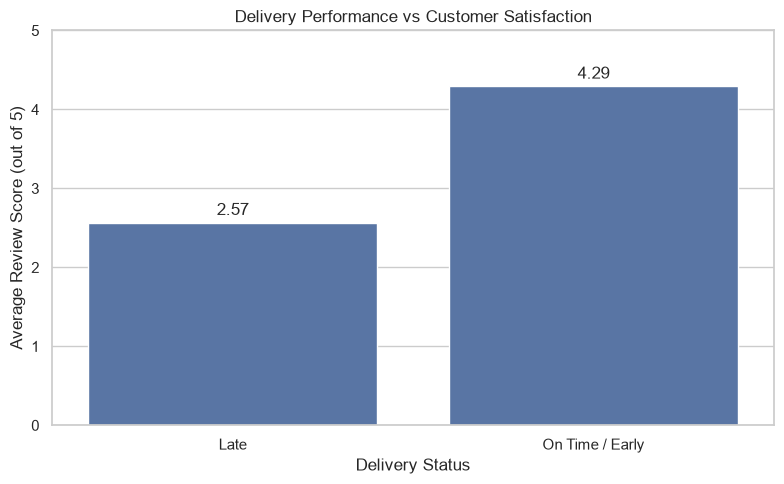

In [44]:
# Compare average review scores by delivery status

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=delivery_summary,
    x="delivery_status",
    y="average_review_score"
)

ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)

plt.title("Delivery Performance vs Customer Satisfaction")
plt.xlabel("Delivery Status")
plt.ylabel("Average Review Score (out of 5)")
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

In [45]:
# Review score distribution

review_distribution = (
    order_reviews["review_score"]
    .value_counts()
    .sort_index()
    .reset_index()
)

review_distribution.columns = ["review_score", "review_count"]

review_distribution["percentage"] = (
    review_distribution["review_count"]
    / review_distribution["review_count"].sum()
    * 100
)

display(review_distribution.round(2))

,review_score,review_count,percentage
0,1,11424,11.51
1,2,3151,3.18
2,3,8179,8.24
3,4,19142,19.29
4,5,57328,57.78


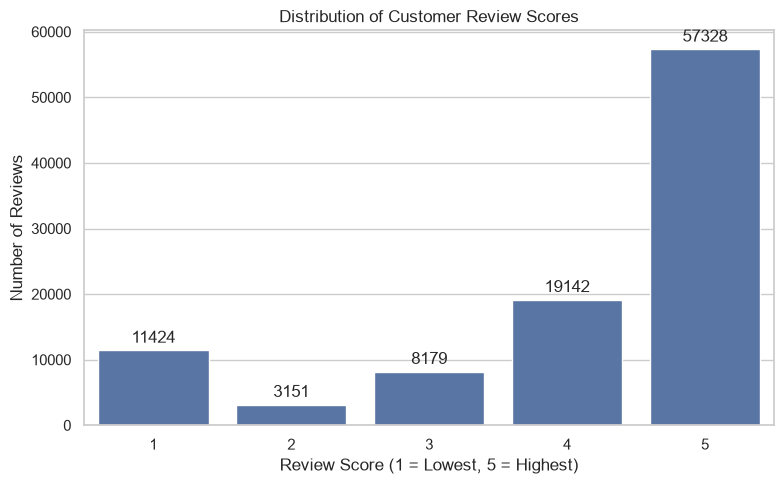

In [46]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=review_distribution,
    x="review_score",
    y="review_count"
)

ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)

plt.title("Distribution of Customer Review Scores")
plt.xlabel("Review Score (1 = Lowest, 5 = Highest)")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

In [47]:
# Compare low-rating percentages by delivery status

delivery_reviews["review_category"] = np.where(
    delivery_reviews["review_score"] <= 2,
    "Low Rating (1-2)",
    np.where(
        delivery_reviews["review_score"] >= 4,
        "High Rating (4-5)",
        "Neutral Rating (3)"
    )
)

rating_comparison = (
    delivery_reviews
    .groupby(["delivery_status", "review_category"])
    .size()
    .reset_index(name="review_count")
)

rating_comparison["percentage"] = (
    rating_comparison["review_count"]
    / rating_comparison.groupby("delivery_status")["review_count"].transform("sum")
    * 100
)

display(rating_comparison.round(2))

,delivery_status,review_category,review_count,percentage
0,Late,High Rating (4-5),2665,33.88
1,Late,Low Rating (1-2),4160,52.89
2,Late,Neutral Rating (3),1040,13.22
3,On Time / Early,High Rating (4-5),73381,82.33
4,On Time / Early,Low Rating (1-2),8186,9.18
5,On Time / Early,Neutral Rating (3),7567,8.49


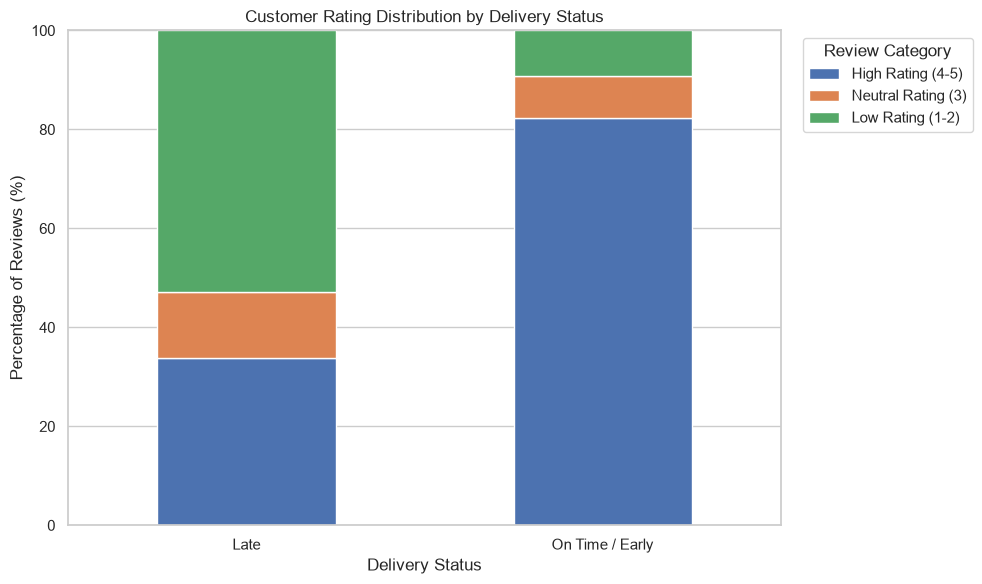

In [48]:
# Stacked percentage chart: rating categories by delivery status

rating_pivot = rating_comparison.pivot(
    index="delivery_status",
    columns="review_category",
    values="percentage"
).fillna(0)

rating_order = [
    "High Rating (4-5)",
    "Neutral Rating (3)",
    "Low Rating (1-2)"
]

rating_pivot = rating_pivot[rating_order]

ax = rating_pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

ax.set_title("Customer Rating Distribution by Delivery Status")
ax.set_xlabel("Delivery Status")
ax.set_ylabel("Percentage of Reviews (%)")
ax.set_ylim(0, 100)
ax.legend(title="Review Category", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [49]:
# Prepare customer-level RFM data

# Keep delivered orders
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

# Attach unique customer IDs
customer_order_data = delivered_orders[
    ["order_id", "customer_id", "order_purchase_timestamp"]
].merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left",
    validate="one_to_one"
)

# Attach product prices to each order
rfm_data = customer_order_data.merge(
    order_items[["order_id", "price"]],
    on="order_id",
    how="inner"
)

# Calculate customer metrics
customer_rfm = (
    rfm_data.groupby("customer_unique_id")
    .agg(
        last_purchase=("order_purchase_timestamp", "max"),
        frequency=("order_id", "nunique"),
        monetary=("price", "sum")
    )
    .reset_index()
)

# Calculate recency relative to the latest purchase date in the data
reference_date = (
    customer_order_data["order_purchase_timestamp"].max()
    + pd.Timedelta(days=1)
)

customer_rfm["recency_days"] = (
    reference_date - customer_rfm["last_purchase"]
).dt.days

display(customer_rfm.head())
print("Unique customers analyzed:", len(customer_rfm))
print("Reference date:", reference_date.date())

,customer_unique_id,last_purchase,frequency,monetary,recency_days
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:27,1,129.90,112
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:27,1,18.90,115
2,0000f46a3911fa3c0805444483337064,2017-03-10 21:05:03,1,69.00,537
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:41,1,25.99,321
4,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:42,1,180.00,288


Unique customers analyzed: 93358
Reference date: 2018-08-30


In [50]:
# Step 1: Calculate RFM scores

# Recency: lower days = better score
customer_rfm["R_score"] = pd.qcut(
    customer_rfm["recency_days"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Frequency: more orders = better score
customer_rfm["F_score"] = pd.qcut(
    customer_rfm["frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Monetary: higher spending = better score
customer_rfm["M_score"] = pd.qcut(
    customer_rfm["monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combined score for basic segmentation
customer_rfm["RFM_score"] = (
    customer_rfm["R_score"]
    + customer_rfm["F_score"]
    + customer_rfm["M_score"]
)

display(
    customer_rfm[
        [
            "customer_unique_id",
            "recency_days",
            "frequency",
            "monetary",
            "R_score",
            "F_score",
            "M_score",
            "RFM_score"
        ]
    ].head(10)
)

,customer_unique_id,recency_days,frequency,monetary,R_score,F_score,M_score,RFM_score
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90,4,1,4,9
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90,4,1,1,6
2,0000f46a3911fa3c0805444483337064,537,1,69.00,1,1,2,4
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99,2,1,1,4
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00,2,1,5,8
5,0004bd2a26a76fe21f786e4fbd80607f,146,1,154.00,4,1,4,9
6,00050ab1314c0e55a6ca13cf7181fecf,132,1,27.99,4,1,1,6
7,00053a61a98854899e70ed204dd4bafe,183,1,382.00,3,1,5,9
8,0005e1862207bf6ccc02e4228effd9a0,543,1,135.00,1,1,4,6
9,0005ef4cd20d2893f0d9fbd94d3c0d97,170,1,104.90,4,1,3,8


In [51]:
# Step 2: Assign customer segments

def assign_segment(row):
    r = row["R_score"]
    f = row["F_score"]
    m = row["M_score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "High-Value Loyal"
    elif r >= 4 and f >= 3:
        return "Loyal / Active"
    elif r >= 4 and f <= 2:
        return "Recent Customers"
    elif r <= 2 and f >= 3:
        return "At-Risk Loyal"
    elif r <= 2 and f <= 2:
        return "Hibernating"
    else:
        return "Regular Customers"

customer_rfm["segment"] = customer_rfm.apply(
    assign_segment,
    axis=1
)

# Summarize segments
segment_summary = (
    customer_rfm.groupby("segment")
    .agg(
        customer_count=("customer_unique_id", "nunique"),
        average_monetary=("monetary", "mean"),
        average_frequency=("frequency", "mean"),
        average_recency_days=("recency_days", "mean")
    )
    .reset_index()
)

segment_summary["percentage"] = (
    segment_summary["customer_count"]
    / segment_summary["customer_count"].sum()
    * 100
)

display(
    segment_summary
    .sort_values("customer_count", ascending=False)
    .round(2)
)

,segment,customer_count,average_monetary,average_frequency,average_recency_days,percentage
0,At-Risk Loyal,22357,143.57,1.05,393.94,23.95
5,Regular Customers,18672,134.11,1.03,219.84,20.00
3,Loyal / Active,15885,96.56,1.02,89.67,17.02
1,Hibernating,14986,140.88,1.00,395.51,16.05
4,Recent Customers,14984,139.31,1.00,90.88,16.05
2,High-Value Loyal,6474,274.16,1.17,90.89,6.93


In [52]:
# Validate customer segmentation results

print("Total customers in RFM:", len(customer_rfm))
print(
    "Unique customer IDs:",
    customer_rfm["customer_unique_id"].nunique()
)

print("\nSegment counts:")
print(customer_rfm["segment"].value_counts())

print("\nCorrect segment summary:")
segment_summary = (
    customer_rfm.groupby("segment")
    .agg(
        customer_count=("customer_unique_id", "nunique"),
        average_monetary=("monetary", "mean"),
        average_frequency=("frequency", "mean"),
        average_recency_days=("recency_days", "mean")
    )
    .reset_index()
)

segment_summary["percentage"] = (
    segment_summary["customer_count"]
    / segment_summary["customer_count"].sum()
    * 100
)

display(
    segment_summary.sort_values(
        "customer_count",
        ascending=False
    ).round(2)
)

print(
    "\nSegment count total:",
    segment_summary["customer_count"].sum()
)

print(
    "Percentage total:",
    round(segment_summary["percentage"].sum(), 2),
    "%"
)

Total customers in RFM: 93358
Unique customer IDs: 93358

Segment counts:
segment
At-Risk Loyal        22357
Regular Customers    18672
Loyal / Active       15885
Hibernating          14986
Recent Customers     14984
High-Value Loyal      6474
Name: count, dtype: int64

Correct segment summary:


,segment,customer_count,average_monetary,average_frequency,average_recency_days,percentage
0,At-Risk Loyal,22357,143.57,1.05,393.94,23.95
5,Regular Customers,18672,134.11,1.03,219.84,20.00
3,Loyal / Active,15885,96.56,1.02,89.67,17.02
1,Hibernating,14986,140.88,1.00,395.51,16.05
4,Recent Customers,14984,139.31,1.00,90.88,16.05
2,High-Value Loyal,6474,274.16,1.17,90.89,6.93



Segment count total: 93358
Percentage total: 100.0 %


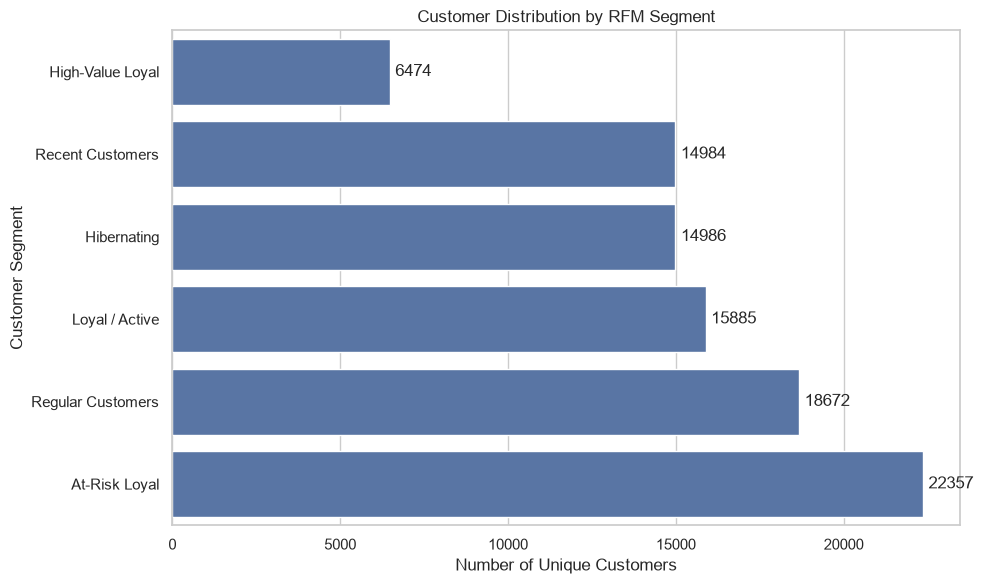

In [53]:
# Customer distribution by RFM segment

segment_plot = segment_summary.sort_values(
    "customer_count",
    ascending=True
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=segment_plot,
    x="customer_count",
    y="segment"
)

ax.bar_label(ax.containers[0], fmt="%.0f", padding=4)

plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Number of Unique Customers")
plt.ylabel("Customer Segment")
plt.tight_layout()
plt.show()

In [54]:
from pathlib import Path

output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

customer_rfm.to_csv(
    output_dir / "customer_rfm_segments.csv",
    index=False
)

segment_summary.to_csv(
    output_dir / "rfm_segment_summary.csv",
    index=False
)

print("RFM files exported successfully.")

RFM files exported successfully.


In [55]:
from pathlib import Path

output_dir = Path("data/processed")

for filename in [
    "customer_rfm_segments.csv",
    "rfm_segment_summary.csv"
]:
    path = output_dir / filename
    print(f"{filename}: {'Found' if path.exists() else 'Missing'}")

customer_rfm_segments.csv: Found
rfm_segment_summary.csv: Found


In [56]:
from pathlib import Path

output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Monthly sales trend
monthly_sales.to_csv(
    output_dir / "monthly_sales.csv",
    index=False
)

# 2. Delivery performance and review scores
delivery_summary.to_csv(
    output_dir / "delivery_performance_summary.csv",
    index=False
)

# 3. Review score distribution
review_distribution.to_csv(
    output_dir / "review_score_distribution.csv",
    index=False
)

# 4. Rating distribution by delivery status
rating_comparison.to_csv(
    output_dir / "delivery_rating_comparison.csv",
    index=False
)

# 5. RFM customer-level segmentation
customer_rfm.to_csv(
    output_dir / "customer_rfm_segments.csv",
    index=False
)

# 6. RFM segment summary
segment_summary.to_csv(
    output_dir / "rfm_segment_summary.csv",
    index=False
)

print("Analysis datasets exported successfully.")
print("\nFiles created:")

for file in sorted(output_dir.glob("*.csv")):
    print(f"{file.name:40} {file.stat().st_size / 1024:.1f} KB")

Analysis datasets exported successfully.

Files created:
customer_rfm_segments.csv                8151.7 KB
delivery_performance_summary.csv         0.2 KB
delivery_rating_comparison.csv           0.4 KB
monthly_sales.csv                        1.1 KB
review_score_distribution.csv            0.2 KB
rfm_segment_summary.csv                  0.6 KB


In [57]:
from pathlib import Path

output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

exports = {
    "monthly_sales.csv": monthly_sales,
    "delivery_performance_summary.csv": delivery_summary,
    "review_score_distribution.csv": review_distribution,
    "delivery_rating_comparison.csv": rating_comparison,
    "customer_rfm_segments.csv": customer_rfm,
    "rfm_segment_summary.csv": segment_summary,
}

for filename, dataframe in exports.items():
    dataframe.to_csv(output_dir / filename, index=False)
    print(f"Saved: {filename} ({len(dataframe):,} rows)")

Saved: monthly_sales.csv (23 rows)
Saved: delivery_performance_summary.csv (2 rows)
Saved: review_score_distribution.csv (5 rows)
Saved: delivery_rating_comparison.csv (6 rows)
Saved: customer_rfm_segments.csv (93,358 rows)
Saved: rfm_segment_summary.csv (6 rows)
